# Bat size, prey characteristics, and season
Run the cells from top to bottom.

In [4]:
from pathlib import Path
import pandas as pd
DATA_PATH = Path("bat_prey_data.xlsx")
bats = pd.read_excel(DATA_PATH, sheet_name=0)
bats = bats.rename(columns={"Body mass of bats (BM)": "bat_mass", "Forearm length (FAL)": "forearm_length", "Predation richness (PR)": "prey_richness", "Mean body mass of birds (MBMB)": "mean_prey_mass"})
bats["season"] = pd.Categorical(bats["Season"], categories=["Spring", "Summer", "Autumn"])
bats["bat_mass_z"] = (bats["bat_mass"] - bats["bat_mass"].mean()) / bats["bat_mass"].std()
bats["mean_prey_mass_num"] = pd.to_numeric(bats["mean_prey_mass"], errors="coerce")
prey_size_data = bats.dropna(subset=["mean_prey_mass_num", "bat_mass_z", "season"])
print(f"Loaded {len(bats)} bat-level observations; {len(prey_size_data)} used for prey-size analysis")
display(bats.head())

Loaded 43 bat-level observations; 42 used for prey-size analysis


,Species,Individuals,Sex,Season,bat_mass,forearm_length,prey_richness,mean_prey_mass,Unnamed: 8,Unnamed: 9,season,bat_mass_z,mean_prey_mass_num
0,Ia io,Spring1,♂,Spring,54.59,74.72,1,8.1,NaN,NaN,Spring,0.051494,8.10
1,Ia io,Spring2,♂,Spring,50.34,77.81,1,8.1,NaN,NaN,Spring,-0.676314,8.10
2,Ia io,Spring3,♂,Spring,42.96,71.68,3,9.14,NaN,NaN,Spring,-1.940132,9.14
3,Ia io,Spring4,♂,Spring,44.52,76.16,1,8.46,NaN,NaN,Spring,-1.672983,8.46
4,Ia io,Spring5,♂,Spring,46.40,74.42,1,10.7,NaN,NaN,Spring,-1.351035,10.70


In [5]:
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
formula = "prey_richness ~ bat_mass_z * C(season)"
poisson_model = smf.glm(formula, data=bats, family=sm.families.Poisson()).fit()
negative_binomial_model = smf.glm(formula, data=bats, family=sm.families.NegativeBinomial()).fit()
poisson_dispersion = (poisson_model.resid_pearson ** 2).sum() / poisson_model.df_resid
prey_size_model = smf.ols("mean_prey_mass_num ~ bat_mass_z * C(season)", data=prey_size_data).fit()
print("Poisson Pearson dispersion:", poisson_dispersion)
print("Poisson AIC:", poisson_model.aic)
print("Negative-binomial AIC:", negative_binomial_model.aic)
print(poisson_model.summary())
print(prey_size_model.summary())

Poisson Pearson dispersion: 0.8684961237787995
Poisson AIC: 145.75837815024724
Negative-binomial AIC: 173.70926249756036
                 Generalized Linear Model Regression Results                  
Dep. Variable:          prey_richness   No. Observations:                   43
Model:                            GLM   Df Residuals:                       37
Model Family:                 Poisson   Df Model:                            5
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -66.879
Date:                Mon, 26 Oct 2026   Deviance:                       28.435
Time:                        20:23:58   Pearson chi2:                     32.1
No. Iterations:                     4   Pseudo R-squ. (CS):             0.1035
Covariance Type:            nonrobust                                         
                                     coef    std err          z      P>|z|      [0.025   

C:\Users\Mira\AppData\Local\Temp\ipykernel_28440\535120886.py:6: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  negative_binomial_model = smf.glm(formula, data=bats, family=sm.families.NegativeBinomial()).fit()


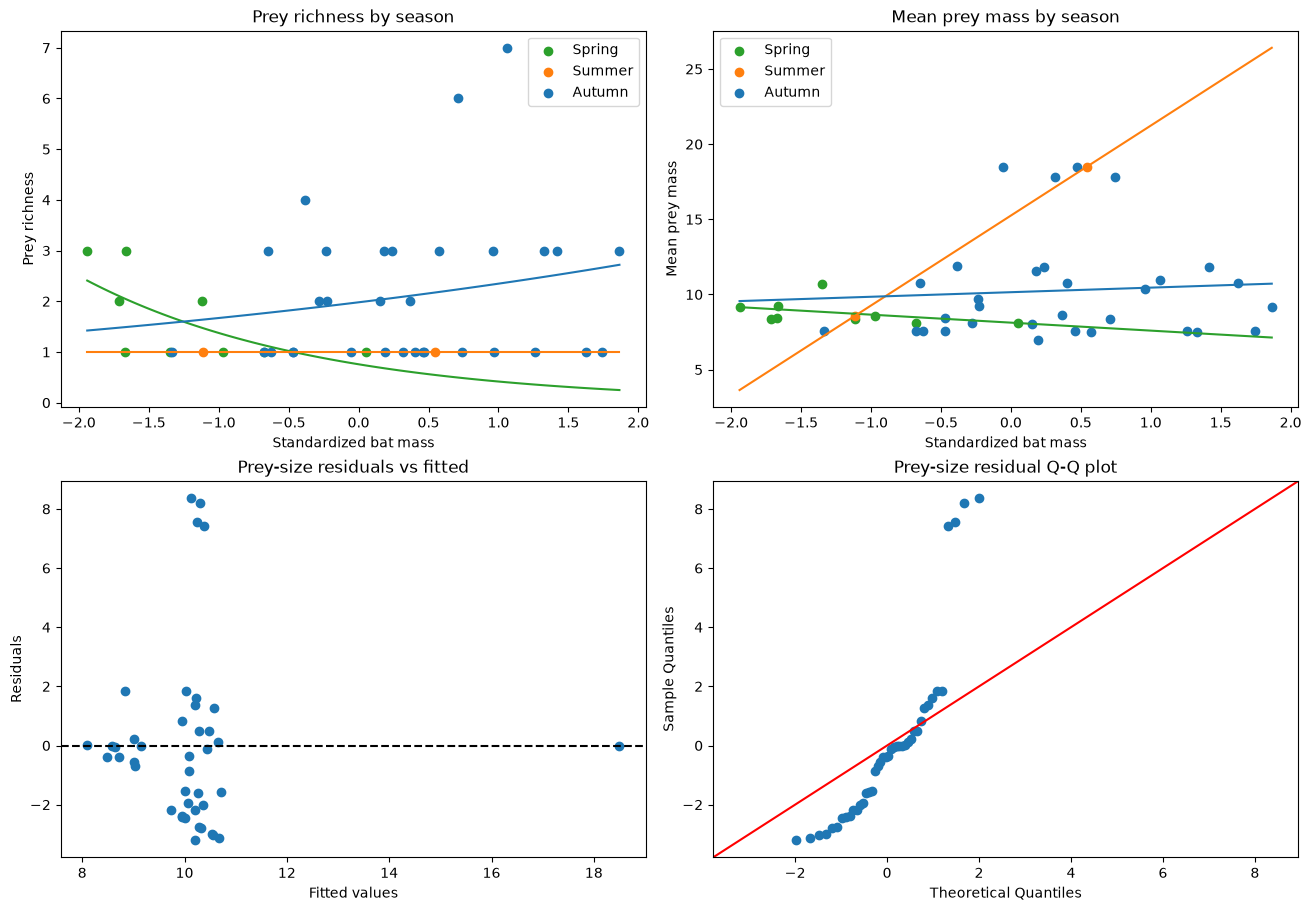

Prey-size Jarque-Bera p-value: 7.823668638930247e-07


In [6]:
import matplotlib.pyplot as plt
from scipy.stats import jarque_bera
mass_grid = np.linspace(bats["bat_mass_z"].min(), bats["bat_mass_z"].max(), 100)
colors = {"Spring": "tab:green", "Summer": "tab:orange", "Autumn": "tab:blue"}
fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
for season, color in colors.items():
    observed = bats[bats["season"] == season]
    observed_size = prey_size_data[prey_size_data["season"] == season]
    grid = pd.DataFrame({"bat_mass_z": mass_grid, "season": season})
    grid["season"] = pd.Categorical(grid["season"], categories=["Spring", "Summer", "Autumn"])
    axes[0, 0].scatter(observed["bat_mass_z"], observed["prey_richness"], color=color, label=season)
    axes[0, 0].plot(mass_grid, poisson_model.predict(grid), color=color)
    axes[0, 1].scatter(observed_size["bat_mass_z"], observed_size["mean_prey_mass_num"], color=color, label=season)
    axes[0, 1].plot(mass_grid, prey_size_model.predict(grid), color=color)
axes[0, 0].set(title="Prey richness by season", xlabel="Standardized bat mass", ylabel="Prey richness")
axes[0, 1].set(title="Mean prey mass by season", xlabel="Standardized bat mass", ylabel="Mean prey mass")
axes[0, 0].legend(); axes[0, 1].legend()
axes[1, 0].scatter(prey_size_model.fittedvalues, prey_size_model.resid)
axes[1, 0].axhline(0, color="black", linestyle="--")
axes[1, 0].set(title="Prey-size residuals vs fitted", xlabel="Fitted values", ylabel="Residuals")
sm.qqplot(prey_size_model.resid, line="45", ax=axes[1, 1]); axes[1, 1].set_title("Prey-size residual Q-Q plot")
plt.show()
print("Prey-size Jarque-Bera p-value:", jarque_bera(prey_size_model.resid).pvalue)